In [1]:
import numpy as np
from argparse import Namespace
from solver.kolmogorov_flow import KolmogorovFlow2d
from generate_data import legacy_solver, gen_data
from prepare_data import shuffle_data, test_data, get_slice

In [2]:
legacy_args = Namespace(
    outdir="./data_low",
    re=10.0,
    res_x=256,
    T=1,             # trajectory 개수
    warmup=10,
    seed=0,

    T_phys=10.0,      # 물리 시간 도메인 [0, 10]
    n_frames=320,     # t축 픽셀 개수
    independent_ic=False,
)
legacy_solver(legacy_args)


0, time cost: 8.885119645041414: 100%|██████████| 1/1 [1:43:54<00:00, 6234.99s/it]


In [ ]:
legacy_args = Namespace(
    outdir="./data_sequence",
    re=1000.0,
    res_x=256,
    T=40,             # trajectory 개수
    warmup=1,
    seed=0,

    T_phys=10.0,      # 물리 시간 도메인 [0, 10]
    n_frames=320,     # t축 픽셀 개수
    independent_ic=False,
)

legacy_solver(legacy_args)


4, time cost: 11.03737362800166:  12%|█▎        | 5/40 [4:22:18<30:36:09, 3147.69s/it]


KeyboardInterrupt: 

In [ ]:
legacy_args = Namespace(
    outdir="./data",
    re=1000.0,
    res_x=256,
    T=40,             # trajectory 개수
    warmup=100.0,
    seed=0,

    T_phys=10.0,      # 물리 시간 도메인 [0, 10]
    n_frames=256,     # t축 픽셀 개수
    independent_ic=True,
)

legacy_solver(legacy_args)


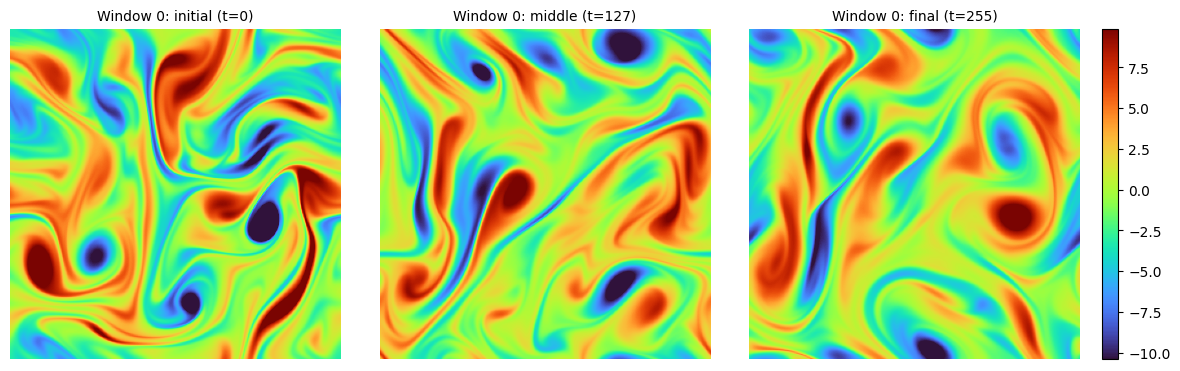

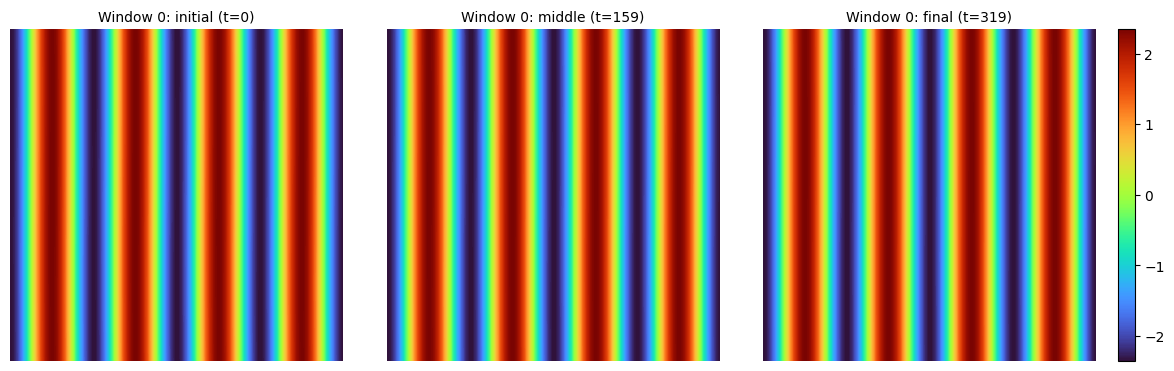

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def plot_init_mid_final_2d_strict(
    npy_path,
    window_idxs=None,
    cmap="turbo",
    origin="lower",
    robust_percentiles=(1, 99),
    mid_mode="lower",   # "lower": 127 (for 256), "upper": 128
):
    data = np.load(npy_path, mmap_mode="r")

    # (n_frames, H, W)도 허용
    if data.ndim == 3:
        data = data[None, ...]
    elif data.ndim != 4:
        raise ValueError(f"Expected 3D or 4D array, got {data.shape}")

    T, n_frames, H, W = data.shape

    if window_idxs is None:
        window_idxs = list(range(T))
    else:
        window_idxs = [int(i) for i in window_idxs if 0 <= int(i) < T]
    if len(window_idxs) == 0:
        raise ValueError("No valid window indices.")

    t0 = 0
    tlast = n_frames - 1
    tmid = (n_frames - 1) // 2 if mid_mode == "lower" else n_frames // 2

    time_idxs = [t0, tmid, tlast]
    time_titles = [f"initial (t={t0})", f"middle (t={tmid})", f"final (t={tlast})"]

    # 공통 vmin/vmax (NaN 방지 포함)
    vals = []
    for widx in window_idxs:
        for t in time_idxs:
            frame = np.asarray(data[widx, t, :, :])
            if frame.shape != (H, W):
                raise ValueError(
                    f"Indexing produced non-2D frame: window={widx}, t={t}, frame.shape={frame.shape}"
                )
            vals.append(frame.ravel())
    vals = np.concatenate(vals)
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        raise ValueError("All values are non-finite (NaN/Inf).")

    vmin, vmax = np.percentile(vals, robust_percentiles)
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmin == vmax:
        vmin, vmax = float(vals.min()), float(vals.max())
    
    nrows = len(window_idxs)
    fig, axes = plt.subplots(
        nrows=nrows, ncols=3,
        figsize=(12, 3.6 * nrows),
        constrained_layout=True,
        squeeze=False
    )

    last_im = None
    for r, widx in enumerate(window_idxs):
        for c, (t, title) in enumerate(zip(time_idxs, time_titles)):
            
            ax = axes[r, c]
            frame = np.asarray(data[widx, t, :, :])
            last_im = ax.imshow(frame, cmap=cmap, origin=origin, vmin=vmin, vmax=vmax)
            ax.set_title(f"Window {widx}: {title}", fontsize=10)
            ax.axis("off")

    # 공통 컬러바 (axes 전체에 붙이기: 레이아웃 덜 깨짐)
    fig.colorbar(last_im, ax=axes, fraction=0.02, pad=0.02)

    plt.show()


# Example
plot_init_mid_final_2d_strict("./data_test/NS-Re1000_T255.npy", mid_mode="lower")
plot_init_mid_final_2d_strict("./data_low/NS-Re10_T319.npy", mid_mode="lower")

In [ ]:
ns_args = Namespace(
    outdir='./data_ns',
    re=40.0,
    x_res=512,
    x_sub=2,
    T=10,
    t_res=128,
    batchsize=4,
    num_batchs=1,
    seed=0
)
ns_paths = gen_data(ns_args)
print('NS dataset files:', ns_paths)
